<p style="text-align:center"><img src="../images/02_banner_raster.png" alt="Working with Raster Data" width="100%"></p>


# Raster Operations

Raster operations are essential techniques in geospatial analysis, enabling the transformation, analysis, and combination of raster datasets for insights into spatial patterns. GeoLattice provides an intuitive, high-level interface for performing a wide range of raster operations, such as clipping, reclassification, focal statistics, raster algebra, resampling, mosaicking, and zonal statistics, built on top of robust GDAL functionality. Whether you're preparing elevation data or performing landscape analysis, GeoLattice streamlines these workflows so you can focus on extracting meaningful information from your raster data.


## Overview

This notebook uses `geolattice.raster.basic_raster_operation`: high-level helpers
that mirror the GDAL `gdal raster` CLI while staying compatible with classic GDAL Python
bindings (`Translate`, `Warp`, `FillNodata`, `Polygonize`, `ComputeProximity`,
`ContourGenerate`, `BuildVRT`, `DEMProcessing`).

The exercises follow the R notes in
`R_Code/working-with-raster-data-r.qmd` and `R_Code/working-with-raster-data.Rmd`:
clip, reclassify, focal statistics, raster algebra, aggregation / disaggregation,
resample, mosaic, stack, and zonal statistics, using Bangladesh and USA DEM data.

| Part | Input | Typical outputs |
|---|---|---|
| **1** Bangladesh | `hilly_DEM_UTM.tif`, `hilly_dem_BTM.tiff`, `HILLY_DEM/*.tiff` | clip, reclass, focal, algebra, aggregate, mosaic |
| **2** USA | `Onondaga_DEM.tif`, `DEM_TILES/*_PROJ.tif`, `CO_ELEV.tif`, `CO_COUNTY_PROJ.shp` | mosaic, stack, zonal stats, proximity, contour |

Written files land under `Data/00_shared/raster_data/output_folder/bangladesh` and `.../usa`.


## API overview (`basic_raster_operation`)

Public helpers and private utilities documented at the top of
`geolattice/raster/basic_raster_operation.py`:

```
- create: Create a new raster dataset
- edit: Edit raster metadata without changing pixel dimensions
- convert: Convert a raster dataset
- resize: Resize a raster without changing georeferenced extents
- unscale: Convert scaled values into unscaled values using band scale/offset
- fill_nodata: Fill nodata regions by interpolation from edges
- neighbors: Compute each pixel from its neighbors / focal statistics
- focal_statistics: Moving-window focal statistics over a single raster band
- calc: Perform raster algebra
- raster_algebra: Evaluate a NumPy-backed raster algebra expression and write the result
- blend: Blend two rasters
- compare: Compare two rasters
- clip: Clip a raster to a bounding box
- reclassify: Reclassify a raster
- resample: Resample a raster to a new resolution
- aggregate: Aggregate a raster by a factor
- disaggregate: Disaggregate a raster by a factor
- mosaic: Mosaic multiple rasters
- stack: Stack multiple rasters
- summarize_raster: Summarize a raster
- zonal_stats: Calculate zonal statistics
- rasterize / polygonize: Polygonize a raster
- proximity: Calculate proximity
- color_map: Create a color map
- contour: Create a contour
- _gdal: Get the GDAL library
- _gdal_ogr: Get the GDAL OGR library
- _band_nodata: Get the nodata value for a band
- _normalize_dtype: Normalize a dtype
- _gdal_dtype: Normalize a GDAL dtype
- _normalize_resample: Normalize a resample method
- _creation_options: Normalize creation options
- _format_from_path: Get the format from a path
- _vector_driver_from_path: Get the vector driver from a path
- _prepare_destination: Prepare a destination
- _broadcast_band_values: Broadcast band values
- _bounds_to_proj_win: Convert bounds to projection window
- _translate: Translate a raster
- _focal_kernel: Get the focal kernel
- _apply_focal: Apply a focal statistic
- _eval_expression: Evaluate an expression
- _eval_node: Evaluate a node
- _zone_summary: Calculate zone summary
- _read_band_array: Read a band array
- _polygonize: Polygonize a raster
- _proximity: Calculate proximity
```

Names starting with `_` are internal helpers. Prefer the public functions imported below.


## Setup

The next cell finds the repository root, points at the Bangladesh and USA raster folders,
creates output directories, and imports the operation helpers.

**Installation.** This notebook needs installation option 1 (vector, raster, CRS and visualization): `pip install "geolattice[core]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and package reloads.
import sys  # mutate sys.path so geolattice can be imported from the repo root
from pathlib import Path  # filesystem paths for locating sample rasters

# Third-party numeric / plotting stack used throughout the notebook.
import matplotlib.pyplot as plt  # figure and axes creation for custom maps
import numpy as np  # array ops for holes, masks, and block aggregates
import pandas as pd  # tabular display of summarize / zonal results
from IPython.display import display  # rich table previews in the notebook

# ===================================================================
# Setup and helpers for basic raster operations and maps.
# Walk up from the working directory to the repo root, reload geolattice.raster,
# import operation helpers, point BD/USA/OUTPUT at sample folders, and
# define show_raster() for quick GeoTIFF summaries.
# ===================================================================

# Resolve the current working directory to an absolute Path.
# Resolve the current working directory as a starting point for the root search.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "raster_data").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find Data/00_shared/vector_data from the working directory.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# Reload so a long-lived Jupyter kernel picks up package edits.
import importlib  # force-reload modules after editing the package source
import geolattice.raster.basic_raster_operation as _bro  # operation helpers module
import geolattice.raster as _raster  # public raster package that re-exports helpers
importlib.reload(_bro)  # refresh basic_raster_operation in this kernel
importlib.reload(_raster)  # refresh the geolattice.raster package exports

# Public raster operation helpers used in the Bangladesh and USA demos.
from geolattice.raster import (
    aggregate,  # coarsen a raster by an integer factor
    blend,  # opacity blend of two aligned rasters
    calc,  # evaluate a short algebra expression on one source
    class_intervals,  # compute quantile / jenks / equal breaks
    clip,  # crop (and optionally mask) a raster to bounds or a cutline
    color_map,  # GDAL color-relief style RGB from a color text file
    compare,  # pixel-wise equality / diff stats between two rasters
    contour,  # vector contour lines at a fixed interval
    convert,  # copy / reformat a raster (dtype, driver, etc.)
    create,  # write a new empty raster with given size / CRS / geotransform
    disaggregate,  # refine a raster by an integer factor
    edit,  # attach metadata (description, scale, offset) without changing pixels
    fill_nodata,  # interpolate into nodata holes from valid edges
    focal_statistics,  # moving-window statistic (mean, sum, ...)
    mosaic,  # merge several rasters into one continuous surface
    neighbors,  # alias for focal_statistics-style neighborhood ops
    open_raster_data,  # open a GeoTIFF (or other GDAL raster) as a dataset
    polygonize,  # convert raster classes to vector polygons
    proximity,  # distance to target pixel values
    raster_algebra,  # NumPy-backed algebra expression written to a new file
    reclassify,  # map value ranges to new integer classes
    rasterize,  # burn vector attributes onto a regular grid
    reclassify_by,  # reclassify using class_intervals styles (quantile, jenks)
    resample,  # match a target resolution with bilinear / nearest
    resize,  # change pixel dimensions while keeping geographic extent
    stack,  # combine rasters into a multi-band GeoTIFF
    summarize_raster,  # count / min / max / mean / percentiles summary
    unscale,  # apply band scale/offset into pixel values
    write_raster_data,  # write a NumPy array as a georeferenced GeoTIFF
    zonal_stats,  # summarize raster values inside polygon zones
)
# Shared map styling helpers from geolattice.viz.
from geolattice.viz import apply_map_style, plot_raster, plot_raster_histogram, plot_rasters

# Sample raster folders and shared output destinations for this tutorial.
BD = ROOT / "Data" / "00_shared" / "raster_data" / "Bangladesh"  # Bangladesh DEM inputs
USA = ROOT / "Data" / "00_shared" / "raster_data" / "USA"  # USA DEM and county inputs
OUTPUT = ROOT / "Data" / "00_shared" / "raster_data" / "output_folder"  # parent for written results
BD_OUT = OUTPUT / "bangladesh" / "ops"  # Bangladesh operation outputs
USA_OUT = OUTPUT / "usa" / "ops"  # USA operation outputs
# Ensure both output folders exist before any write.
for folder in (BD_OUT, USA_OUT):
    folder.mkdir(parents=True, exist_ok=True)  # create nested dirs as needed

# Apply the shared GeoLattice map style (fonts, colors, spines).
apply_map_style()


# helper: print size, resolution, bounds, CRS, and nodata for a raster path
def show_raster(path, title=None):
    """Print size, resolution, bounds, CRS, and nodata for a raster path."""
    # Normalize the path argument to a Path object.
    path = Path(path)
    # Open the dataset and print a short metadata summary.
    with open_raster_data(path) as ds:
        gt = ds.geotransform  # affine geotransform (origin, pixel size, rotation)
        print(f"path:    {path.name}")  # file name only for readability
        print(f"size:    {ds.width} x {ds.height}  bands={ds.band_count}")  # pixel grid
        print(f"res:     {abs(gt[1]):.4f} x {abs(gt[5]):.4f}")  # absolute pixel size
        print(f"bounds:  {ds.bounds}")  # geographic extent
        print(f"crs:     {ds.crs}")  # coordinate reference system
        print(f"nodata:  {ds.get_band(1).nodata}")  # band-1 nodata flag
        # Optional extra label when the caller passes a title.
        if title:
            print(f"title:   {title}")


# Confirm which folders the notebook will read from and write to.
print(f"Bangladesh: {BD}")
print(f"USA:        {USA}")
print(f"BD output:  {BD_OUT}")
print(f"USA output: {USA_OUT}")


Bangladesh: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/Bangladesh
USA:        /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/USA
BD output:  /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/bangladesh/ops
USA output: /home/zia207/Github/GeoLattice/Data/00_shared/raster_data/output_folder/usa/ops


## Part 1: Bangladesh

### Inspect the hilly DEM

`hilly_DEM_UTM.tif` is a 250 m SRTM elevation mosaic for the hilly districts of
Bangladesh (same dataset as the R `terra::rast(...)` example). `hilly_dem_BTM.tiff`
is the Bangladesh Transverse Mercator version used for many of the R processing steps.


In [2]:
# Paths to the UTM and BTM versions of the hilly Bangladesh DEM.
dem_utm = BD / "hilly_DEM_UTM.tif"  # 250 m SRTM mosaic in UTM
dem_btm = BD / "hilly_dem_BTM.tiff"  # same surface in Bangladesh Transverse Mercator
# Confirm both input files are present on disk.
print(f"UTM exists: {dem_utm.exists()}")
print(f"BTM exists: {dem_btm.exists()}")
print()  # blank line between existence checks and metadata
# Print metadata for the UTM DEM.
show_raster(dem_utm, "hilly DEM (UTM)")
print()  # blank line between the two summaries
# Print metadata for the BTM DEM (used by most Bangladesh steps below).
show_raster(dem_btm, "hilly DEM (BTM)")


UTM exists: True
BTM exists: True

path:    hilly_DEM_UTM.tif
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814053, 2295017.262541298, 778300.3746814053, 2627267.262541298)
crs:     PROJCS["WGS_1984_Transverse_Mercator",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -3.3999999521443642e+38
title:   hilly DEM (UTM)

path:    hilly_dem_BTM.tiff
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.

### Summarize and plot

`summarize_raster` reports count / min / max / mean / std and selected percentiles
(similar to R `summary(dem)`).


,value
count,310665
min,-7.796429
max,985.049622
mean,109.007889
std,129.049986
sum,33864935.903503
percentiles,"{'p2': 3.0354053211212157, 'p25': 29.240074157..."


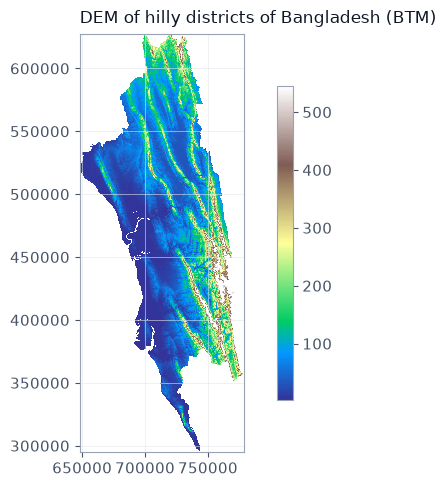

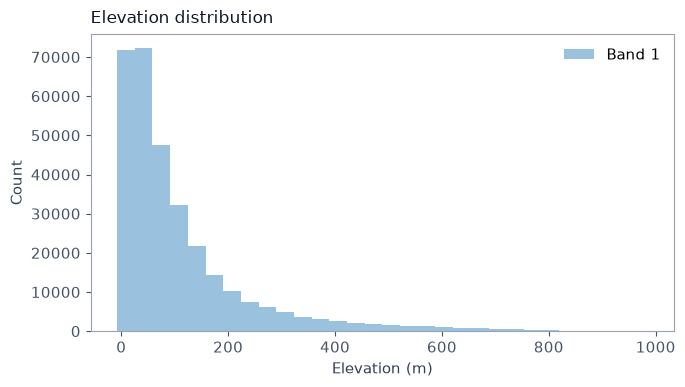

In [3]:
# Compute count / min / max / mean / std and selected percentiles for the BTM DEM.
stats = summarize_raster(dem_btm, percentiles=(2, 25, 50, 75, 98))
# Show the summary dict as a one-column table in the notebook.
display(pd.Series(stats).to_frame("value"))

# Draw a terrain-colored map of the BTM DEM (robust stretch hides outliers).
ax = plot_raster(
    dem_btm,  # path to the elevation GeoTIFF
    title="DEM of hilly districts of Bangladesh (BTM)",  # map title
    cmap="terrain",  # elevation-friendly colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch for contrast
    show=False,  # defer display so we can call plt.show() ourselves
)
# Render the figure in the notebook.
plt.show()

# Draw an elevation histogram for the same DEM.
ax = plot_raster_histogram(
    dem_btm,  # path to the elevation GeoTIFF
    bins=30,  # number of histogram bins
    title="Elevation distribution",  # chart title
    show=False,  # defer display
)
# Label the x-axis with elevation units.
ax.set_xlabel("Elevation (m)")
# Render the histogram figure.
plt.show()


### Create / convert / resize / edit / unscale

These match the GDAL-style create / convert / resize / edit / unscale helpers.


path:    empty_template.tif
size:    64 x 64  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 611267.2625412983, 664050.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -9999.0
title:   Empty Raster Template (float32)

converted -> hilly_dem_BTM_copy.tif
path:    hilly_dem_BTM_copy.tif
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)

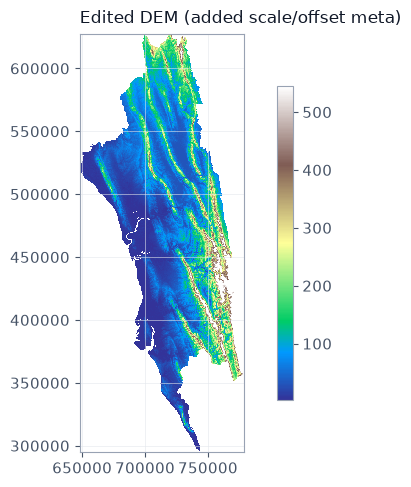

unscale -> hilly_dem_unscaled.tif
path:    hilly_dem_unscaled.tif
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan
title:   Unscaled DEM


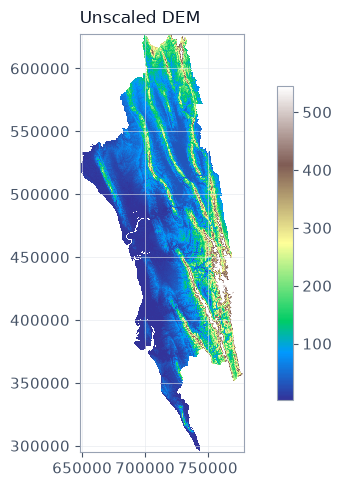

compare(self): equal=True max_abs_diff=0.0


In [4]:
# Create: empty float32 template with the DEM geotransform / CRS and visualize it.
# Open the BTM DEM to copy its CRS, geotransform, and size into the template.
with open_raster_data(dem_btm) as ds:
    template_crs = ds.crs  # coordinate reference system for the new file
    template_gt = ds.geotransform  # affine transform (origin + pixel size)
    w, h = ds.width, ds.height  # full DEM width and height in pixels

# Destination path for a small empty template GeoTIFF.
empty_path = BD_OUT / "empty_template.tif"
# Write a small float32 raster filled with nodata (-9999).
create(
    empty_path,  # output path
    width=min(w, 64),  # cap width at 64 pixels for a lightweight demo
    height=min(h, 64),  # cap height at 64 pixels
    bands=1,  # single-band template
    dtype="float32",  # floating-point pixels
    crs=template_crs,  # same CRS as the DEM
    geotransform=template_gt,  # same origin / pixel size as the DEM
    nodata=-9999,  # nodata flag written to the band
    fill=-9999,  # fill every pixel with nodata
    overwrite=True,  # replace any previous demo file
)

# Visualize the created empty raster metadata.
show_raster(empty_path, title="Empty Raster Template (float32)")

# Convert: GeoTIFF copy (optionally change dtype / format).
converted = BD_OUT / "hilly_dem_BTM_copy.tif"  # output path for the converted copy
convert(dem_btm, converted, overwrite=True)  # copy dem_btm to a new GeoTIFF
print(f"\nconverted -> {converted.name}")  # confirm the written file name

# Visualize the converted raster metadata.
show_raster(converted, title="Converted DEM (copy)")

# Resize: change pixel dimensions, keep geographic extent, then visualize.
resized = BD_OUT / "hilly_dem_BTM_half_px.tif"  # output path for the half-resolution grid
# Shrink width and height to 50% with bilinear resampling (extent unchanged).
resize(dem_btm, resized, width_pct=50, height_pct=50, resample="bilinear", overwrite=True)
show_raster(resized, title="Resized DEM (50% px)")  # print resized metadata

# Edit: attach description / scale / offset metadata without changing pixels.
scaled_meta = BD_OUT / "hilly_dem_scaled_meta.tif"  # output path for metadata edit
edit(
    dem_btm,  # source DEM
    scaled_meta,  # destination with updated metadata
    description="Elevation (m) with demo scale/offset",  # band description string
    scale=1.0,  # demo scale factor (identity)
    offset=0.0,  # demo offset (identity)
    overwrite=True,  # replace any previous demo file
)
print(f"edit -> {scaled_meta.name}")  # confirm the written file name
show_raster(scaled_meta, title="Edited DEM (added scale/offset meta)")  # print metadata
# Plot the edited DEM (pixels unchanged; only metadata differs).
ax = plot_raster(
    scaled_meta,
    title="Edited DEM (added scale/offset meta)",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
plt.show()  # render the edited DEM map

# Unscale: apply band scale/offset into pixel values (here scale=1, offset=0).
unscaled = BD_OUT / "hilly_dem_unscaled.tif"  # output path for unscaled values
unscale(scaled_meta, unscaled, dtype="float32", overwrite=True)  # bake scale/offset into pixels
print(f"unscale -> {unscaled.name}")  # confirm the written file name
show_raster(unscaled, title="Unscaled DEM")  # print unscaled metadata
# Plot the unscaled DEM.
ax = plot_raster(
    unscaled,
    title="Unscaled DEM",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
plt.show()  # render the unscaled DEM map

# Compare a DEM against itself to demonstrate compare() equality stats.
cmp = compare(dem_utm, dem_utm)  # self-compare should report equal=True
print(
    "compare(self): equal={equal} max_abs_diff={max_abs_diff}".format(**cmp)
)  # print key equality fields


### Clip

Raster clipping refers to the process of extracting a portion of a raster dataset based on a specified spatial extent or boundary. This is a common operation in geospatial analysis when you need to focus on a specific area of interest within a larger raster dataset. Raster clipping can help reduce the dataset's size, improve processing efficiency, and facilitate analysis that's relevant to a particular region.

Clip by projected bounds (same idea as R `crop()` / extent). Bounds are
`(minx, miny, maxx, maxy)` in the raster CRS. Here we take a window over the
southern hills (Bandarban / Cox's Bazar region in BTM meters).


full bounds: Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
clip bounds: (667587.8746814046, 295017.2625412984, 758762.8746814046, 411304.76254129835)
path:    hilly_dem_BTM_clipped.tif
size:    365 x 465  bands=1
res:     249.7945 x 250.0806
bounds:  Bounds(667587.8746814046, 295017.2625412984, 758762.8746814046, 411304.76254129835)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan


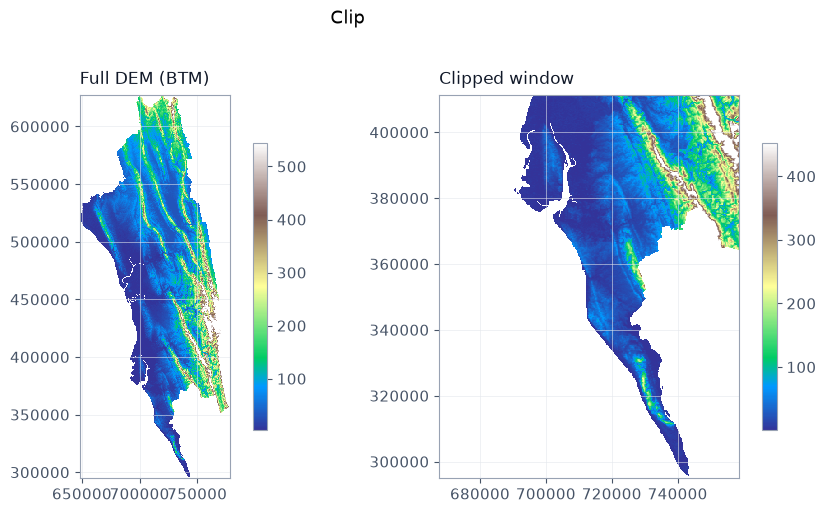

In [5]:
# Open the BTM DEM and build a southern window from its projected bounds.
with open_raster_data(dem_btm) as ds:
    # Unpack full extent as (minx, miny, maxx, maxy) in the raster CRS.
    minx, miny, maxx, maxy = ds.bounds.to_tuple()
    # Southern window ~ lower third of the mosaic (Bandarban / Cox's Bazar region).
    clip_bounds = (
        minx + 0.15 * (maxx - minx),  # inset 15% from the west
        miny,  # keep the southern edge
        maxx - 0.15 * (maxx - minx),  # inset 15% from the east
        miny + 0.35 * (maxy - miny),  # take the lower ~35% of the height
    )
    print("full bounds:", ds.bounds)  # print the full DEM extent
    print("clip bounds:", clip_bounds)  # print the crop window

# Destination path for the clipped GeoTIFF.
clipped = BD_OUT / "hilly_dem_BTM_clipped.tif"
# Crop the DEM to the projected bounds window.
clip(dem_btm, clipped, bounds=clip_bounds, overwrite=True)
# Print metadata for the clipped result.
show_raster(clipped)

# Side-by-side map: full DEM vs clipped southern window.
fig, axes = plot_rasters(
    [dem_btm, clipped],  # input paths for the two panels
    titles=["Full DEM (BTM)", "Clipped window"],  # panel titles
    figsize=(10, 5),  # figure size in inches
    cmap="terrain",  # elevation colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
fig.suptitle("Clip", y=1.02)  # shared figure title above the panels
fig.tight_layout()  # reduce unused whitespace
plt.show()  # render the comparison figure


**Clip to Bandarban district (vector cutline)**

Same workflow as the R notes (`crop` + `mask` on Bandarban): filter
`ADM2_EN == "Bandarban"` from `Data/00_shared/vector_data/Bangladesh/bd_district_BTM.shp`,
then `clip(..., cutline=..., crop_to_cutline=True)` to crop and mask the DEM.

districts: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh/bd_district_BTM.shp
exists:    True
Bandarban features: 1
bounds: (np.float64(712762.8133498818), np.float64(344101.4694432481), np.float64(778101.7724792161), np.float64(473977.39559145644))
path:    bandarban_dem_BTM.tif
size:    261 x 518  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(712800.3746814046, 344267.2625412984, 778050.3746814046, 473767.26254129835)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]

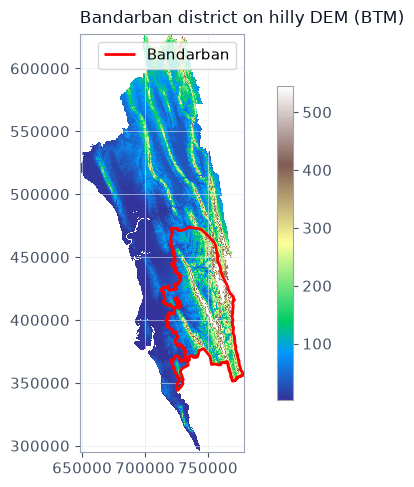

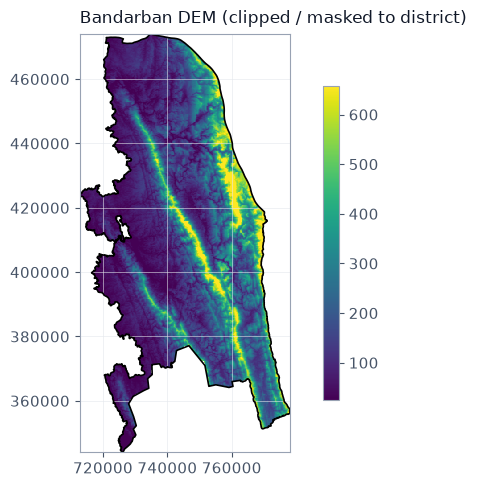

In [6]:
# GeoPandas is used to filter the Bandarban district polygon cutline.
import geopandas as gpd  # read district shapefile and filter by name

# Path to Bangladesh districts in the same BTM projection as the DEM.
district_shp = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "bd_district_BTM.shp"
print(f"districts: {district_shp}")  # show the shapefile path
print(f"exists:    {district_shp.exists()}")  # confirm the file is present

# Read all districts, then keep only Bandarban.
bd_dist = gpd.read_file(district_shp)  # full district GeoDataFrame
bandarban_dist = (
    bd_dist.rename(columns={"ADM2_EN": "DIST_Name"})  # rename admin name column
    .query('DIST_Name == "Bandarban"')  # filter to Bandarban only
    .copy()  # materialize a standalone GeoDataFrame
)
print(f"Bandarban features: {len(bandarban_dist)}")  # should be 1 feature
print(f"bounds: {tuple(bandarban_dist.total_bounds)}")  # district bounding box

# Cutline for GDAL clip (crop + mask), same idea as R crop/mask.
bandarban_cutline = BD_OUT / "bandarban_district.gpkg"  # GeoPackage cutline path
bandarban_dist.to_file(bandarban_cutline, driver="GPKG")  # write the cutline layer

# Destination path for the Bandarban-masked DEM.
bandarban_dem = BD_OUT / "bandarban_dem_BTM.tif"
# Clip and mask the BTM DEM to the Bandarban district polygon.
clip(
    dem_btm,  # source DEM
    bandarban_dem,  # cropped / masked output
    cutline=bandarban_cutline,  # vector polygon cutline
    crop_to_cutline=True,  # shrink the grid to the cutline envelope
    overwrite=True,  # replace any previous demo file
)
# Print metadata for the Bandarban DEM.
show_raster(bandarban_dem)

# Full DEM with Bandarban boundary overlaid in red.
ax = plot_raster(
    dem_btm,
    title="Bandarban district on hilly DEM (BTM)",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
# Draw the district outline on top of the DEM.
bandarban_dist.boundary.plot(ax=ax, edgecolor="red", linewidth=2, label="Bandarban")
ax.legend(loc="upper right")  # show the boundary legend
plt.show()  # render the overview map

# Clipped / masked DEM for Bandarban only.
ax = plot_raster(
    bandarban_dem,
    title="Bandarban DEM (clipped / masked to district)",
    cmap="viridis",
    kind="general",
    robust=True,
    show=False,
)
# Zoom the axes to the district bounds.
xmin, ymin, xmax, ymax = bandarban_dist.total_bounds  # district envelope
bandarban_dist.boundary.plot(ax=ax, edgecolor="black", linewidth=1.2)  # outline
ax.set_xlim(xmin, xmax)  # clip x-axis to the district
ax.set_ylim(ymin, ymax)  # clip y-axis to the district
plt.show()  # render the Bandarban-only map


Clipped output: `Data/00_shared/raster_data/output_folder/bangladesh/ops/bandarban_dem_BTM.tif`.


### Fill nodata

`fill_nodata` interpolates from valid edges into nodata regions
(`gdal.FillNodata`). We introduce a small hole in the clip, then fill it.


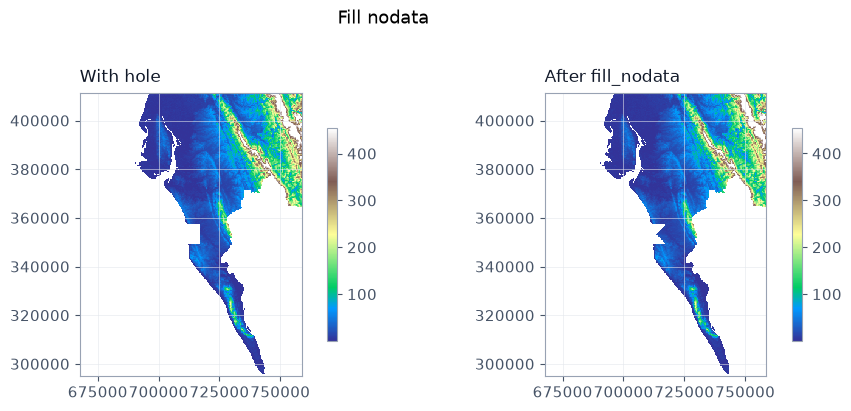

In [7]:
# Read the clipped DEM into a NumPy array and capture georeferencing for rewrite.
with open_raster_data(clipped) as ds:
    arr = np.asarray(ds.read(bands=1), dtype=np.float32)  # band-1 elevation array
    crs = ds.crs  # coordinate reference system to preserve on write
    gt = ds.geotransform  # affine transform to preserve on write
    nodata = ds.get_band(1).nodata  # existing nodata flag (may be None)
    # Fall back to -9999 when the source has no nodata or uses NaN.
    if nodata is None or (isinstance(nodata, float) and np.isnan(nodata)):
        nodata = -9999.0  # synthetic nodata used for the punched hole

# Punch a slightly smaller rectangular hole near the center.
h, w = arr.shape  # array height and width in pixels
hole_half_size = 16  # half-width of the hole (32x32 pixels total)
r0, r1 = h // 2 - hole_half_size, h // 2 + hole_half_size  # row slice of the hole
c0, c1 = w // 2 - hole_half_size, w // 2 + hole_half_size  # column slice of the hole
holed = arr.copy()  # copy so the original clipped array stays intact
holed[r0:r1, c0:c1] = nodata  # set the center window to nodata
holed_path = BD_OUT / "hilly_dem_with_hole.tif"  # path for the holed GeoTIFF
# Write the holed array as a georeferenced GeoTIFF.
write_raster_data(holed_path, holed, crs=crs, geotransform=gt, nodata=nodata, overwrite=True)

# Destination path for the filled result.
filled = BD_OUT / "hilly_dem_filled.tif"
# Interpolate into the hole from valid edges (gdal.FillNodata).
fill_nodata(holed_path, filled, max_distance=50, smoothing_iterations=1, overwrite=True)

# Side-by-side map: holed DEM vs filled DEM.
fig, axes = plot_rasters(
    [holed_path, filled],  # before / after paths
    titles=["With hole", "After fill_nodata"],  # panel titles
    figsize=(10, 4),  # figure size in inches
    cmap="terrain",  # elevation colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
fig.suptitle("Fill nodata", y=1.02)  # shared figure title
fig.tight_layout()  # tighten spacing
plt.show()  # render the comparison figure


### Reclassify

Raster reclassification is the process of assigning new values to the cells of a raster dataset based on predefined criteria. This operation is commonly used in geospatial analysis to reclassify continuous raster data (e.g., elevation, temperature) into discrete categories (e.g., low, medium, high).

**Histogram**

Raster reclassification is the process of assigning new values to the cells of a raster dataset based on predefined criteria. This operation is commonly used in geospatial analysis to reclassify continuous raster data (e.g., elevation, temperature) into discrete categories (e.g., low, medium, high).


| Class | Elevation (m) | Label |
|---|---|---|
| 1 | &lt; 200 | Low |
| 2 | 200-400 | Medium |
| 3 | >= 400 | High |

`reclassify` rules are `(min, max, new)` half-open ranges `[min, max)`, or
`(value, new)` for exact matches.


path:    hilly_dem_reclass.tif
size:    521 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778300.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan


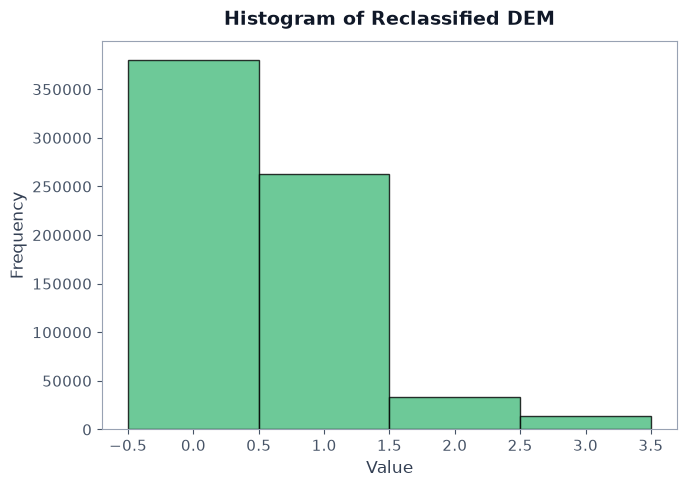

In [8]:
# Destination path for the elevation class GeoTIFF.
reclass_path = BD_OUT / "hilly_dem_reclass.tif"
# Map elevation ranges to integer classes: 1=Low, 2=Medium, 3=High.
reclassify(
    dem_btm,  # source BTM DEM
    reclass_path,  # classified output
    mapping=[
        (-200, 200, 1),  # elevations in [-200, 200) -> class 1 (Low)
        (200, 400, 2),  # elevations in [200, 400) -> class 2 (Medium)
        (400, 2000, 3),  # elevations in [400, 2000) -> class 3 (High)
    ],
    default=0,  # anything outside the ranges becomes 0
    overwrite=True,  # replace any previous demo file
)
# Print metadata for the reclassified raster.
show_raster(reclass_path)

# Updated: Raster histogram visualization helper for discrete class counts.
def raster_histogram(raster_path, bins=20, title="Raster Value Histogram", figsize=(7, 5), color="#5a95d6"):
    """Plot histogram of raster values."""
    # Read band 1 and drop NaNs before plotting.
    with open_raster_data(raster_path) as ds:
        arr = ds.read(1)  # band-1 values
        arr = arr.astype(float)  # float for NaN masking
        arr = arr[~np.isnan(arr)]  # drop invalid pixels
    
    # Draw a simple matplotlib histogram.
    plt.figure(figsize=figsize)  # create a new figure
    plt.hist(arr, bins=bins, color=color, edgecolor="k", alpha=0.8)  # class / value counts
    plt.xlabel("Value", fontsize=12)  # x-axis label
    plt.ylabel("Frequency", fontsize=12)  # y-axis label
    plt.title(title, fontsize=14, weight='bold', pad=12)  # chart title
    plt.tight_layout()  # tighten spacing
    plt.show()  # render the histogram

# Show histogram for the reclassified raster with bins centered on 0..3.
raster_histogram(reclass_path, bins=[-0.5,0.5,1.5,2.5,3.5], title="Histogram of Reclassified DEM", color="#49bc7f")


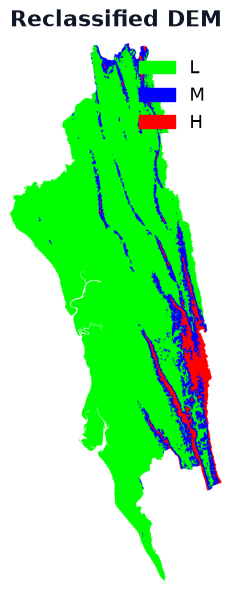

In [9]:
# Reclassified DEM: 1=Low, 2=Medium, 3=High (color map: green, blue, red for L/M/H).
reclass_path = BD_OUT / "hilly_dem_reclass.tif"  # path written by the previous cell

# Show the map like the provided image: L=green, M=blue, H=red; patch legend; simple box; axis off.
import matplotlib.patches as mpatches  # Patch artists for the custom L/M/H legend

# Colors and labels matching the image (green, blue, red).
class_colors = ["#00FF00", "#0000FF", "#FF0000"]  # green, blue, red
class_labels = ["L", "M", "H"]  # short class labels for the legend

# Read the reclassified array and prepare a masked index for ListedColormap.
with open_raster_data(reclass_path) as ds:
    arr = ds.read(1)  # integer class values
    arr = np.ma.masked_where(arr == 0, arr)   # mask '0' (default / outside mapping)
    # Remap: expected classes 1,2,3 -> indices 0,1,2 for the colormap.
    idx = arr - 1

# Create a tall figure similar to the R spplot layout.
fig, ax = plt.subplots(figsize=(4.3, 7))
# Draw the class index image with a discrete green/blue/red colormap.
im = ax.imshow(idx, cmap=plt.matplotlib.colors.ListedColormap(class_colors), vmin=0, vmax=2, origin='upper')
ax.set_title("Reclassified DEM", fontsize=16, fontweight='bold', pad=12)  # map title
ax.axis('off')  # hide tick marks and axis spines by default

# Set a thin border box like the R plot.
for spine in ax.spines.values():
    spine.set_edgecolor('black')  # black frame
    spine.set_linewidth(1)  # thin line
    spine.set_visible(True)  # keep the frame visible even with axis off

# Custom legend (R-style: color squares with L, M, H).
patches = [mpatches.Patch(color=col, label=lab) for col, lab in zip(class_colors, class_labels)]
legend = ax.legend(handles=patches, loc='upper right', frameon=False, borderaxespad=0.5, fontsize=13)
plt.show()  # render the reclassified map


**Quantile**  


quantile breaks: [-4, 7, 19, 35, 49, 65, 88, 120, 170, 276, 888]


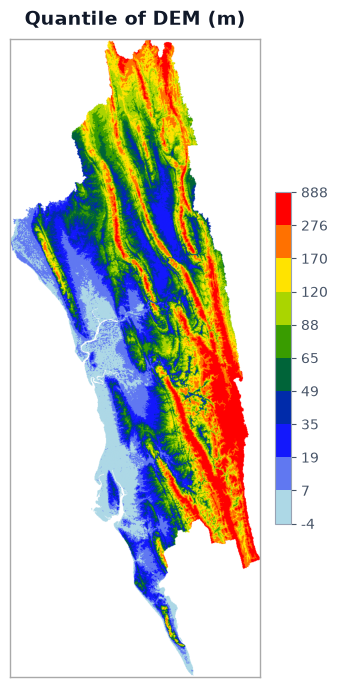

In [10]:
# Colormap helpers for a quantile-colored elevation map.
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# Quantile breaks (R classInt) and classified GeoTIFFs.
q10_path = BD_OUT / "hilly_dem_q10.tif"  # 10-class quantile reclass output
jenks_path = BD_OUT / "hilly_dem_jenks.tif"  # 5-class jenks reclass output

# Compute 10 quantile break points on the BTM DEM.
breaks = class_intervals(dem_btm, n=10, style="quantile")
# Round breaks to integers for readable colorbar labels.
at = [int(round(b)) for b in breaks]
print("quantile breaks:", at)  # print the break list

# Write quantile and jenks classified GeoTIFFs.
reclassify_by(dem_btm, q10_path, n=10, style="quantile", overwrite=True)
reclassify_by(dem_btm, jenks_path, n=5, style="jenks", overwrite=True)

# Map like R spplot(dem, at=quantile_breaks, col.regions=rgb.palette).
rgb_palette = LinearSegmentedColormap.from_list(
    "dem_quantile",  # colormap name
    ["lightblue", "blue", "green", "yellow", "red"],  # low -> high colors
    N=100,  # interpolated color resolution
)
# Bound each break to a colormap index (clip out-of-range values).
norm = BoundaryNorm(breaks, ncolors=rgb_palette.N, clip=True)

# Read the continuous DEM and mask nodata / invalid pixels.
with open_raster_data(dem_btm) as ds:
    arr = np.asarray(ds.read(1), dtype=float)  # elevation as float
    nodata = ds.get_band(1).nodata  # band nodata flag
# Mask pixels that match the nodata value when one is set.
if nodata is not None:
    arr = np.ma.masked_equal(arr, nodata)
arr = np.ma.masked_invalid(arr)  # also mask NaN / Inf

# Create a tall figure and draw the quantile-colored DEM.
fig, ax = plt.subplots(figsize=(4.3, 7))
im = ax.imshow(arr, cmap=rgb_palette, norm=norm, origin="upper")  # elevation image
ax.set_title("Quantile of DEM (m)", fontsize=14, fontweight="bold", pad=10)  # title
ax.set_xticks([])  # hide x ticks
ax.set_yticks([])  # hide y ticks
# Draw a thin dark-grey border around the map.
for spine in ax.spines.values():
    spine.set_edgecolor("darkgrey")
    spine.set_linewidth(1)
    spine.set_visible(True)

# Colorbar labeled with the integer quantile breaks.
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_ticks(breaks)  # tick positions at each break
cbar.set_ticklabels([str(v) for v in at])  # integer labels
cbar.ax.tick_params(labelsize=10)  # slightly smaller tick text
plt.tight_layout()  # tighten spacing
plt.show()  # render the quantile map


### Focal statistics / neighbors

Focal statistics, also known as neighborhood or moving window statistics, involve performing calculations on a raster dataset using a moving window that slides over each cell. This window defines a local area around each cell, and calculations are carried out based on the values within that window. This technique is commonly used for various geospatial analysis tasks, such as smoothing, edge detection, and texture analysis.

In R, you can perform focal statistics using packages like raster and terra.

To illustrate the neighborhood processing for Focal Statistics calculating a Sum statistic, consider the processing cell with a value of 5 in the following diagram. A rectangular 3 by 3 cell neighborhood shape is specified. The sum of the values of the neighboring cells (3 + 2 + 3 + 4 + 2 + 1 + 4 = 19) plus the value of the processing cell (5) equals 24 (19 + 5 = 24). So a value of 24 is given to the cell in the output raster in the same location as the processing cell in the input raster.

Moving-window stats (`focal_statistics` / alias `neighbors`) correspond to R
`terra::focal()`. Window `size` must be an odd integer.


/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/geolattice/raster/basic_raster_operation.py:1945: RuntimeWarning: Mean of empty slice
  return np.nanmean(flat, axis=2)


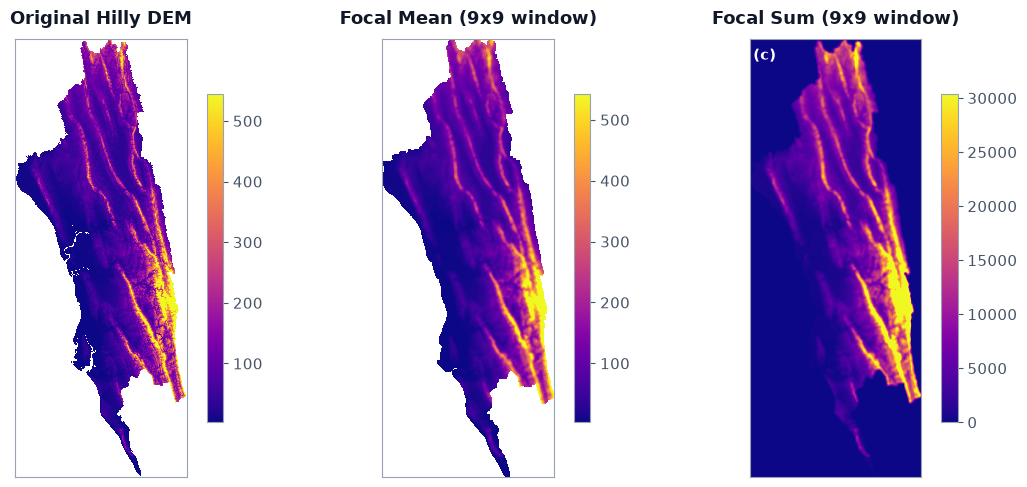

In [11]:
# Focal stats on the hilly DEM.
focal_src = dem_btm  # use hilly DEM as the focal input
focal_mean = BD_OUT / "hilly_dem_focal_mean.tif"  # 9x9 mean output
focal_sum = BD_OUT / "hilly_dem_focal_sum.tif"  # 9x9 sum output

# Moving-window mean and sum (odd window size required).
focal_statistics(focal_src, focal_mean, statistic="mean", size=9, overwrite=True)
neighbors(focal_src, focal_sum, statistic="sum", size=9, overwrite=True)

# Three-panel layout like the reference figure (plasma + colorbars, with full titles).
fig, axes = plt.subplots(1, 3, figsize=(12, 5))  # one row, three columns
raster_paths = [focal_src, focal_mean, focal_sum]  # original / mean / sum
full_titles = [
    "Original Hilly DEM",  # panel (a) title
    "Focal Mean (9x9 window)",  # panel (b) title
    "Focal Sum (9x9 window)",  # panel (c) title
]
letters = ["(a)", "(b)", "(c)"]  # letter labels drawn on each panel

# Now actually show the title above each map panel.
for ax, title in zip(axes, full_titles):
    ax.set_title(title, fontsize=13, fontweight='bold', pad=11)  # bold panel title

# Plot each raster into its axes and annotate with a letter.
for ax, path, letter in zip(axes, raster_paths, letters):
    plot_raster(
        path,  # raster path for this panel
        ax=ax,  # target axes
        title=None,  # title already set above
        cmap="plasma",  # shared colormap
        kind="general",  # single-band continuous display
        robust=True,  # percentile stretch
        add_colorbar=True,  # show a colorbar beside each panel
        show=False,  # defer display until the figure is complete
    )
    ax.set_xticks([])  # hide x ticks
    ax.set_yticks([])  # hide y ticks
    ax.set_xlabel("")  # clear default x label
    ax.set_ylabel("")  # clear default y label
    # Keep a visible frame around each panel.
    for spine in ax.spines.values():
        spine.set_visible(True)
    # Draw the panel letter in the upper-left corner.
    ax.text(
        0.02,  # x in axes fraction
        0.98,  # y in axes fraction
        letter,  # "(a)", "(b)", or "(c)"
        transform=ax.transAxes,  # place in axes coordinates
        va="top",  # vertical alignment
        ha="left",  # horizontal alignment
        fontsize=11,
        fontweight="bold",
        color="white",  # readable on plasma backgrounds
    )

fig.subplots_adjust(wspace=0.25)  # space between panels for colorbars
fig.tight_layout()  # final spacing pass
plt.show()  # render the three-panel figure


### Raster algebra

Raster algebra, also known as map algebra, involves performing mathematical operations on raster datasets to create new raster outputs. It's a fundamental technique in geospatial analysis that allows you to combine, modify, and analyze raster data using various arithmetic and logical operations.

Convert meters to feet with `calc` / `raster_algebra` (R: `dem * 3.28084`).
Bands from a single source are available as `A` / `band1`.


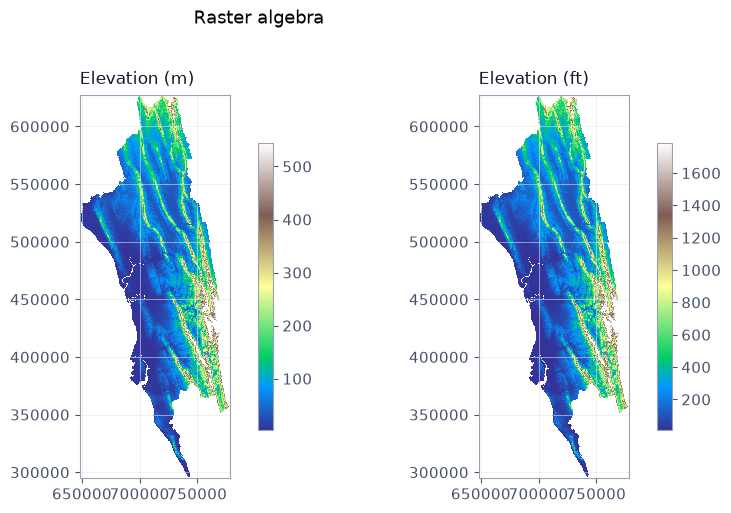

meters: 109.00788921668955
feet:   357.6374432354064


In [12]:
# Convert elevation from meters to feet with calc (R: dem * 3.28084).
dem_feet = BD_OUT / "hilly_dem_feet.tif"  # output path for feet
calc("A * 3.28084", dem_feet, source=dem_btm, overwrite=True)  # A is band 1 of dem_btm

# Scale feet by 1/1000 with raster_algebra (demo of a second expression).
dem_feet_k = BD_OUT / "hilly_dem_feet_x1000.tif"  # output path for feet/1000
raster_algebra("A / 1000", dem_feet_k, source=dem_feet, overwrite=True)

# Side-by-side map: meters vs feet.
fig, axes = plot_rasters(
    [dem_btm, dem_feet],  # meters and feet paths
    titles=["Elevation (m)", "Elevation (ft)"],  # panel titles
    figsize=(10, 5),  # figure size in inches
    cmap="terrain",  # elevation colormap
    kind="general",  # single-band continuous display
    robust=True,  # percentile stretch
    show=False,  # defer display
)
fig.suptitle("Raster algebra", y=1.02)  # shared figure title
fig.tight_layout()  # tighten spacing
plt.show()  # render the comparison figure

# Print mean elevation in both units as a quick sanity check.
print("meters:", summarize_raster(dem_btm)["mean"])
print("feet:  ", summarize_raster(dem_feet)["mean"])


### Aggregate / disaggregate / resample

Raster aggregation involves converting a high-resolution raster dataset into a lower-resolution raster dataset by grouping or summarizing cells into larger cells. This process reduces the level of detail in the data and can help improve processing efficiency and visualization for large datasets. Aggregation is often used when working with raster data at different scales, or when matching the resolution of one raster to another for analysis or visualization purposes.

* `aggregate(factor=2)` -> ~500 m cells from 250 m (R `aggregate(..., fact=2)`)
* `disaggregate(factor=5)` -> ~50 m cells (R `disagg(..., fact=5)`)
* `resample` matches a target resolution with bilinear (or nearest) interpolation


--- 250 m (source mosaic) ---
path:    hilly_dem_mosaic.tif
size:    520 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778050.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan

--- 500 m (aggregate) ---
path:    hilly_dem_500m.tif
size:    260 x 665  bands=1
res:     500.0000 x 500.0000
bounds:  Bounds(648050.3746814046, 294767.2625412984, 778050.3746814046, 627267.2625412983)
crs:     PROJCS["unknown

/tmp/ipykernel_1161893/705929943.py:52: RuntimeWarning: Mean of empty slice
  mean_500 = np.nanmean(blocks, axis=(1, 3))  # block mean
/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


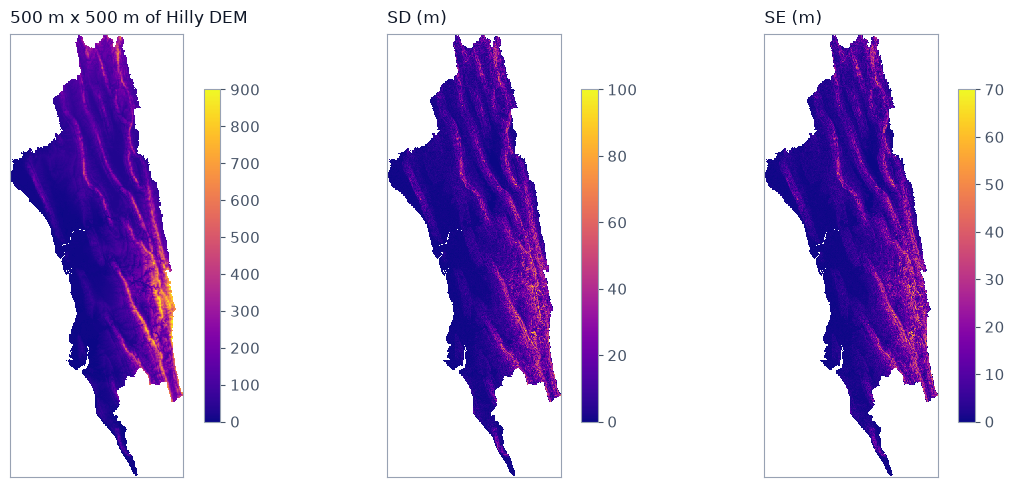

In [13]:
# Re-import write_raster_data for the block mean / SD / SE GeoTIFF writes below.
from geolattice.raster import write_raster_data

# Use Hilly DEM (mosaic) for aggregation, disaggregation, and resampling.
hilly_dem_path = BD_OUT / "hilly_dem_mosaic.tif"  # mosaic written in the mosaic cells

# Output paths for coarsened, refined, and resampled products.
agg_500 = BD_OUT / "hilly_dem_500m.tif"  # factor-2 aggregate (~500 m)
disagg_50 = BD_OUT / "hilly_dem_50m.tif"  # factor-5 disaggregate (~50 m)
resamp_250 = BD_OUT / "hilly_dem_resampled_250m.tif"  # resample 500 m back to 250 m

# Aggregate by 2 (average), disaggregate by 5 (bilinear), then resample to original res.
aggregate(hilly_dem_path, agg_500, factor=2, method="average", overwrite=True)
disaggregate(hilly_dem_path, disagg_50, factor=5, method="bilinear", overwrite=True)
# Read the source pixel size so resample can target the original resolution.
with open_raster_data(hilly_dem_path) as ds:
    xres, yres = abs(ds.geotransform[1]), abs(ds.geotransform[5])  # absolute pixel sizes
# Resample the 500 m aggregate back toward the original 250 m grid.
resample(agg_500, resamp_250, resolution=(xres, yres), method="bilinear", overwrite=True)

# Print metadata for each resolution product.
for label, path in [
    ("250 m (source mosaic)", hilly_dem_path),
    ("500 m (aggregate)", agg_500),
    ("50 m (disaggregate)", disagg_50),
    ("250 m (resampled from 500)", resamp_250),
]:
    print(f"--- {label} ---")  # section header for the console summary
    show_raster(path)  # print size / res / bounds / CRS
    print()  # blank line between products

# Calculate mean, SD, SE on 500 m blocks of Hilly DEM (mosaic) (fact=2).
agg_src = hilly_dem_path  # alias for the mosaic source
# Read the mosaic array and georeferencing for a custom 2x2 block summary.
with open_raster_data(agg_src) as ds:
    arr = np.asarray(ds.read(bands=1), dtype=np.float64)  # elevation as float64
    gt = list(ds.geotransform)  # mutable geotransform list
    crs = ds.crs  # CRS to reuse on the written products
    nodata = ds.get_band(1).nodata  # band nodata flag

# Replace nodata with NaN so nanmean / nanstd ignore those pixels.
if nodata is not None and not (isinstance(nodata, float) and np.isnan(nodata)):
    work = np.where(arr == nodata, np.nan, arr)  # nodata -> NaN
else:
    work = arr.copy()  # no nodata flag: work on a copy of the array

# Trim to even dimensions so 2x2 reshape has no leftover edge.
h, w = work.shape  # full height and width
h2, w2 = h - (h % 2), w - (w % 2)  # even sizes
# Reshape into non-overlapping 2x2 blocks.
blocks = work[:h2, :w2].reshape(h2 // 2, 2, w2 // 2, 2)
mean_500 = np.nanmean(blocks, axis=(1, 3))  # block mean
sd_500 = np.nanstd(blocks, axis=(1, 3))  # block standard deviation
se_500 = sd_500 / np.sqrt(2.0)  # standard error used in this demo (sd / sqrt(2))

# Geotransform with doubled pixel size for the 500 m products.
gt_500 = (gt[0], gt[1] * 2, gt[2], gt[3], gt[4], gt[5] * 2)
mean_path = BD_OUT / "hilly_dem_agg_mean_500m.tif"  # mean GeoTIFF path
sd_path = BD_OUT / "hilly_dem_agg_sd_500m.tif"  # SD GeoTIFF path
se_path = BD_OUT / "hilly_dem_agg_se_500m.tif"  # SE GeoTIFF path
# Write mean / SD / SE as float32 GeoTIFFs.
write_raster_data(mean_path, mean_500.astype(np.float32), crs=crs, geotransform=gt_500, overwrite=True)
write_raster_data(sd_path, sd_500.astype(np.float32), crs=crs, geotransform=gt_500, overwrite=True)
write_raster_data(se_path, se_500.astype(np.float32), crs=crs, geotransform=gt_500, overwrite=True)

# 1x3 panel: mean / SD / SE (plasma + colorbars).
fig, axes = plt.subplots(1, 3, figsize=(12, 5))  # one row, three columns
panel = [
    (mean_path, "500 m x 500 m of Hilly DEM", (0, 900)),  # mean with fixed stretch
    (sd_path, "SD (m)", (0, 100)),  # SD with fixed stretch
    (se_path, "SE (m)", (0, 70)),  # SE with fixed stretch
]
# Plot each summary raster into its panel with a fixed vmin/vmax.
for ax, (path, title, (vmin, vmax)) in zip(axes, panel):
    plot_raster(
        path,  # summary GeoTIFF
        ax=ax,  # target axes
        title=title,  # panel title
        cmap="plasma",  # shared colormap
        kind="general",  # single-band continuous display
        robust=False,  # use explicit vmin/vmax instead
        vmin=vmin,  # lower color stretch
        vmax=vmax,  # upper color stretch
        add_colorbar=True,  # show a colorbar
        show=False,  # defer display
    )
    ax.set_xticks([])  # hide x ticks
    ax.set_yticks([])  # hide y ticks
    ax.set_xlabel("")  # clear x label
    ax.set_ylabel("")  # clear y label

fig.subplots_adjust(wspace=0.25)  # space for colorbars
fig.tight_layout()  # final spacing pass
plt.show()  # render the mean / SD / SE figure


### Mosaic

Raster mosaicking is the process of combining multiple raster datasets to create a single, continuous raster dataset that covers a larger geographic area. Mosaicking is commonly used when you have multiple raster images that need to be merged into a seamless and complete representation of a larger region. This technique is often employed in remote sensing, geospatial analysis, and cartography.

Merge the five district DEMs in `HILLY_DEM/` into one continuous surface
(R `do.call(merge, ...)` / `terra::merge`).


5 tiles:
  bandarban_dem_BTM.tiff
  chittagong_dem_BTM.tiff
  cox_bazar_dem_BTM.tiff
  khagrachhari_dem_BTM.tiff
  rangamati_dem_BTM.tiff


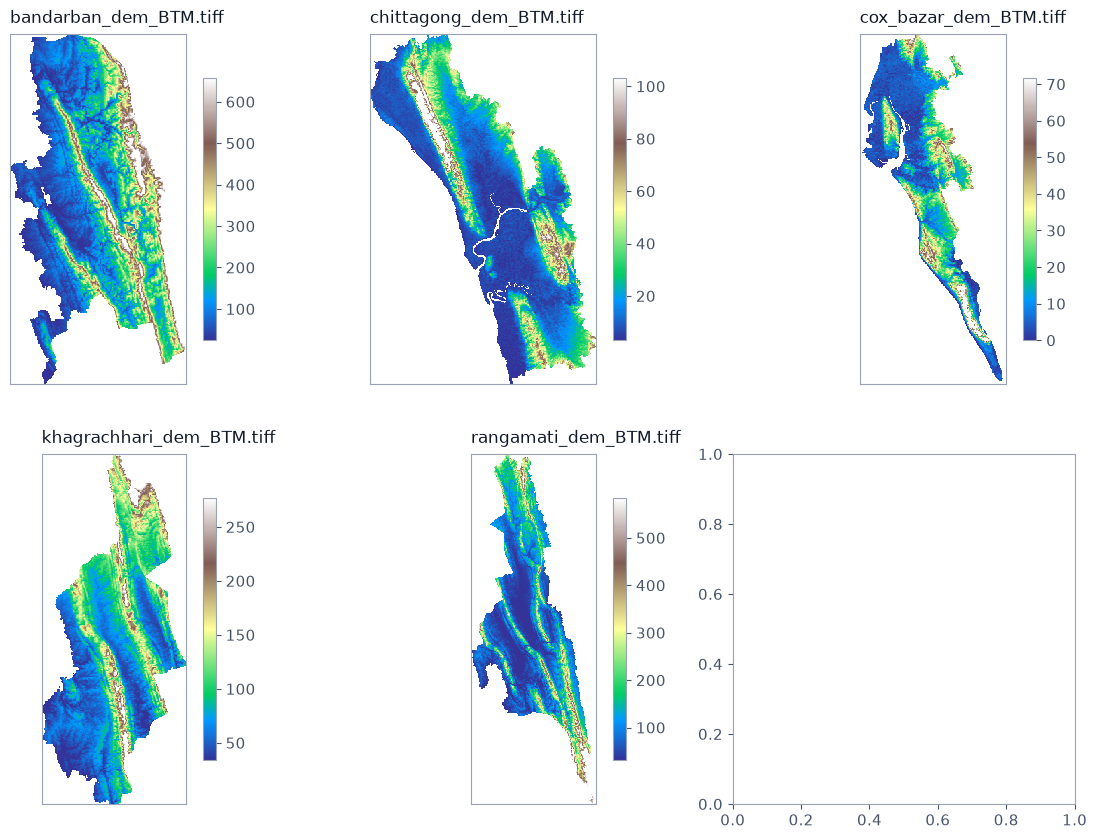

In [14]:
# Collect the five district DEM tiles under HILLY_DEM/ (sorted for stable order).
tile_paths = sorted((BD / "HILLY_DEM").glob("*_dem_BTM.tiff"))
print(f"{len(tile_paths)} tiles:")  # how many tiles were found
# Print each tile file name.
for path in tile_paths:
    print(f"  {path.name}")
# Plot all tiles in a 2x3 grid (sixth axes left unused if only five tiles).
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, path in zip(axes.ravel(), tile_paths):
    # Draw one district DEM into the next available axes.
    plot_raster(path, ax=ax, title=path.name, cmap="terrain", kind="general", robust=True, show=False)
    ax.set_xticks([])  # hide x ticks
    ax.set_yticks([])  # hide y ticks


path:    hilly_dem_mosaic.tif
size:    520 x 1329  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(648050.3746814046, 295017.2625412984, 778050.3746814046, 627267.2625412983)
crs:     PROJCS["unknown",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  nan


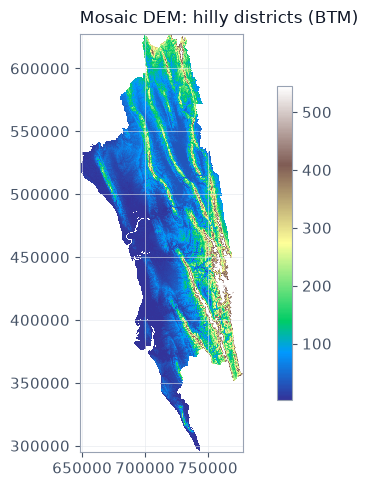

In [15]:
# Destination path for the merged hilly DEM mosaic.
mosaic_path = BD_OUT / "hilly_dem_mosaic.tif"
# Merge the district tiles into one continuous surface.
mosaic(tile_paths, mosaic_path, overwrite=True)
# Print metadata for the mosaic.
show_raster(mosaic_path)

# Plot the mosaic DEM with a terrain colormap.
ax = plot_raster(
    mosaic_path,
    title="Mosaic DEM: hilly districts (BTM)",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
plt.show()  # render the mosaic map


### Blend / compare / polygonize / proximity / contour / color map

A few more helpers on the Bangladesh mosaic / reclass products.


self-compare: {'equal': True, 'max_abs_diff': 0.0, 'rmse': 0.0}


polygonize -> hilly_dem_reclass.gpkg
contour -> hilly_dem_contours.gpkg


Warning 1: Pixels not square, distances will be inaccurate.


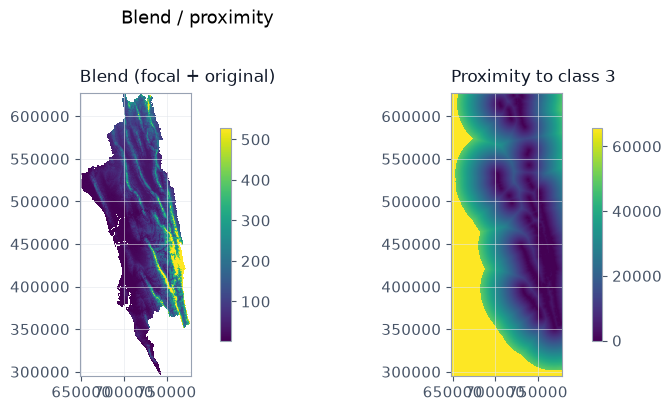

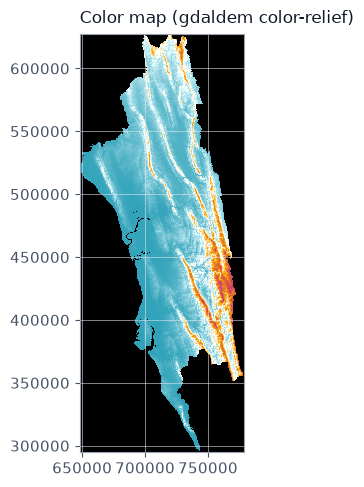

In [16]:
# Blend Bandarban DEM with its focal mean (same shape required).
blended = BD_OUT / "bandarban_dem_blend.tif"  # blend output path
# Opacity 0.4 blends focal_mean over focal_src (aligned grids from earlier cells).
blend(focal_mean, focal_src, blended, opacity=0.4, overwrite=True)

# Compare mosaic tiles vs full BTM (shapes may differ); here self-compare UTM DEM.
cmp_self = compare(dem_utm, dem_utm)  # equality / RMSE dictionary
print("self-compare:", {k: cmp_self[k] for k in ("equal", "max_abs_diff", "rmse")})

# Polygonize reclassified DEM (vector polygons per class).
poly_path = BD_OUT / "hilly_dem_reclass.gpkg"  # vector output path
polygonize(reclass_path, poly_path, field_name="elev_class", overwrite=True)
print(f"polygonize -> {poly_path.name}")  # confirm written file

# Proximity to high-elevation class (value 3).
prox = BD_OUT / "hilly_dem_proximity_high.tif"  # distance raster path
proximity(reclass_path, prox, target_values=[3], max_distance=50000, overwrite=True)

# Contours every 100 m from the BTM DEM.
contours = BD_OUT / "hilly_dem_contours.gpkg"  # contour GeoPackage path
contour(dem_btm, contours, interval=100, overwrite=True)
print(f"contour -> {contours.name}")  # confirm written file

# Color-relief style RGB from a GDAL color text file.
color_txt = BD_OUT / "dem_colors.txt"  # GDAL color-relief text path
# Write elevation -> RGBA rules (nv = nodata; then elevation breakpoints).
color_txt.write_text(
    "\n".join(
        [
            "nv 0 0 0 0",  # nodata -> transparent black
            "0 46 154 88",  # low elevation green
            "200 255 255 128",  # mid-low yellow-green
            "400 245 152 0",  # mid-high orange
            "800 200 50 50",  # high red
            "1200 255 255 255",  # peaks white
        ]
    )
    + "\n"  # trailing newline expected by GDAL color files
)
colored = BD_OUT / "hilly_dem_colored.tif"  # RGB color-relief output
color_map(dem_btm, colored, color_txt, overwrite=True)  # apply the color text

# Side-by-side map: blend result and proximity to class 3.
fig, axes = plot_rasters(
    [blended, prox],
    titles=["Blend (focal + original)", "Proximity to class 3"],
    figsize=(10, 4),
    cmap="viridis",
    kind="general",
    robust=True,
    show=False,
)
fig.suptitle("Blend / proximity", y=1.02)  # shared figure title
fig.tight_layout()  # tighten spacing
plt.show()  # render the blend / proximity figure

# Plot the RGB color-relief product.
ax = plot_raster(
    colored,
    title="Color map (gdaldem color-relief)",
    kind="rgb",  # interpret as multi-band RGB
    show=False,
)
plt.show()  # render the color-relief map


### Vector to raster

Convert district polygons to a raster grid (R ``raster::rasterize``). Here we burn
district **Boro** rice production into a 250 m grid covering the shapefile extent,
then scale to thousand metric tons with ``calc``.


rice districts: /home/zia207/Github/GeoLattice/Data/00_shared/vector_data/Bangladesh/bd_district_rice_production_2018_2019_BTM.shp
exists:         True


path:    boro_production_x1000.tif
size:    1919 x 2674  bands=1
res:     250.0000 x 250.0000
bounds:  Bounds(298487.810888788, 278578.09791320935, 778237.810888788, 947078.0979132093)
crs:     PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",90],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",-2000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -9999.0
title:   Boro production (MT x 1000)


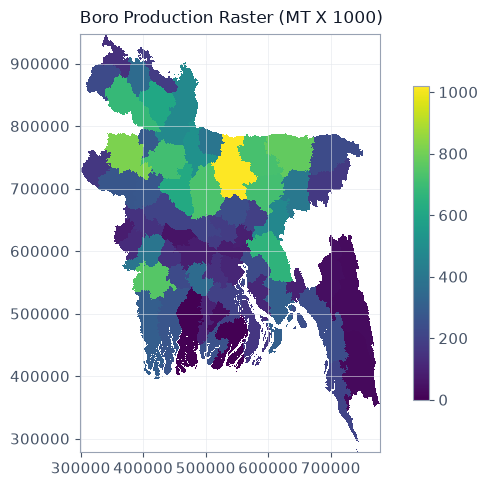

In [17]:
# Path to district rice-production polygons (BTM), used as rasterize input.
rice_shp = ROOT / "Data" / "00_shared" / "vector_data" / "Bangladesh" / "bd_district_rice_production_2018_2019_BTM.shp"
print(f"rice districts: {rice_shp}")  # show the shapefile path
print(f"exists:         {rice_shp.exists()}")  # confirm the file is present

# Optional: write Boro_1000 attribute (same as R poly$Boro_1000 <- poly$Boro/1000).
import geopandas as gpd  # read the rice shapefile and add Boro_1000

rice_gdf = gpd.read_file(rice_shp)  # district rice GeoDataFrame
rice_gdf["Boro_1000"] = rice_gdf["Boro"] / 1000  # scale Boro to thousand metric tons
rice_boro = BD_OUT / "bd_rice_boro1000.gpkg"  # GeoPackage with the scaled attribute
# Keep name / production columns plus geometry when writing the cutline-style input.
rice_gdf[["ADM2_EN", "Boro", "Boro_1000", "geometry"]].to_file(rice_boro, driver="GPKG")

# Rasterize at 250 m (same resolution idea as the hilly DEM / R tutorial).
boro_raster = BD_OUT / "boro_production_x1000.tif"  # burned production grid
rasterize(
    rice_boro,  # vector source with Boro_1000
    boro_raster,  # output GeoTIFF
    attribute="Boro_1000",  # burn this numeric field into pixels
    resolution=250,  # 250 m cell size
    nodata=-9999,  # nodata outside polygons
    all_touched=True,  # include every cell touched by a polygon
    overwrite=True,  # replace any previous demo file
)
# Print metadata for the production raster.
show_raster(boro_raster, "Boro production (MT x 1000)")

# Plot the Boro production grid.
ax = plot_raster(
    boro_raster,
    title="Boro Production Raster (MT X 1000)",
    cmap="viridis",
    kind="general",
    robust=True,
    show=False,
)
plt.show()  # render the production map


## Part 2: USA

### Inspect Onondaga and Colorado elevation

Onondaga County DEM (WGS 84) and Colorado elevation (`CO_ELEV.tif`, Albers-style
projected meters) mirror the USA examples in the R / projection notebooks.


Onondaga: True
CO elev:  True
NY proj:  True

path:    Onondaga_DEM.tif
size:    534 x 443  bands=1
res:     0.0011 x 0.0011
bounds:  Bounds(-76.50012580544984, 42.77138668060471, -75.89506961211198, 43.27333404698799)
crs:     EPSG:4326
nodata:  -3.4028230607370965e+38

path:    CO_ELEV.tif
size:    128 x 101  bands=1
res:     5000.0000 x 5000.0000
bounds:  Bounds(-1145285.0, 1568795.0, -505285.0, 2073795.0)
crs:     PROJCS["unnamed",GEOGCS["GRS 1980(IUGG, 1980)",DATUM["unknown",SPHEROID["GRS80",6378137,298.257222101],TOWGS84[0,0,0,0,0,0,0]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",23],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -3.3999999521443642e+38

path

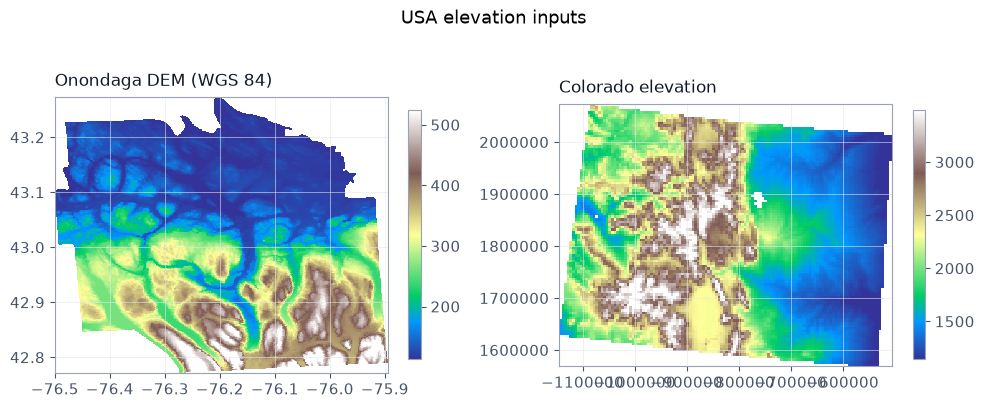

In [18]:
# Paths to USA elevation inputs used in Part 2.
onondaga = USA / "Onondaga_DEM.tif"  # Onondaga County DEM (WGS 84)
co_elev = USA / "CO_ELEV.tif"  # Colorado elevation (projected meters)
ny_proj = USA / "NY_DEM0_PROJ.tif"  # optional projected NY DEM tile
# Confirm which inputs are present on disk.
print(f"Onondaga: {onondaga.exists()}")
print(f"CO elev:  {co_elev.exists()}")
print(f"NY proj:  {ny_proj.exists()}")
print()  # blank line before metadata
# Print metadata for Onondaga and Colorado DEMs.
show_raster(onondaga)
print()
show_raster(co_elev)
print()
# Print the optional projected NY tile when it exists.
if ny_proj.exists():
    show_raster(ny_proj)

# Side-by-side map of the two primary USA elevation inputs.
fig, axes = plot_rasters(
    [onondaga, co_elev],
    titles=["Onondaga DEM (WGS 84)", "Colorado elevation"],
    figsize=(10, 4),
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
fig.suptitle("USA elevation inputs", y=1.02)  # shared figure title
fig.tight_layout()  # tighten spacing
plt.show()  # render the USA inputs figure


### Mosaic Onondaga tiles

Four projected tiles in `DEM_TILES/` mosaicked into one county DEM (same idea as
the Bangladesh `HILLY_DEM` merge).


4 tiles:
  Onondaga_DEM0_PROJ.tif
  Onondaga_DEM1_PROJ.tif
  Onondaga_DEM2_PROJ.tif
  Onondaga_DEM3_PROJ.tif
path:    onondaga_mosaic.tif
size:    677 x 534  bands=1
res:     89.8750 x 124.0000
bounds:  Bounds(1563322.7032641422, 751976.4158569482, 1624168.0782641422, 818192.4158569482)
crs:     PROJCS["unnamed",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -3.3999999521443642e+38


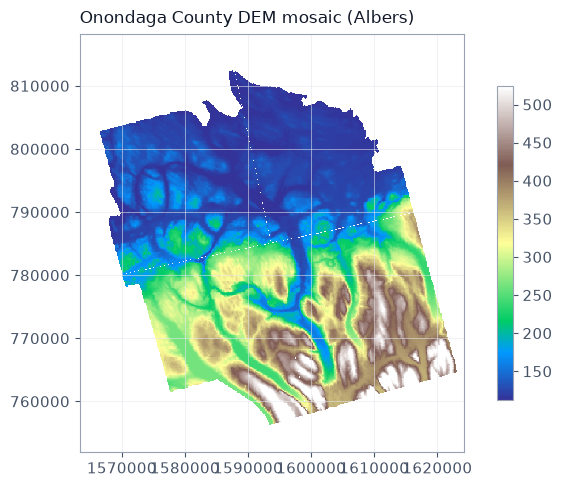

In [19]:
# Collect the four projected Onondaga DEM tiles (Onondaga_DEM0..3_PROJ.tif).
usa_tiles = sorted((USA / "DEM_TILES").glob("Onondaga_DEM[0-9]_PROJ.tif"))
print(f"{len(usa_tiles)} tiles:")  # how many tiles were found
# Print each tile file name.
for path in usa_tiles:
    print(f"  {path.name}")

# Destination path for the Onondaga county mosaic.
usa_mosaic = USA_OUT / "onondaga_mosaic.tif"
# Merge the projected tiles into one county DEM.
mosaic(usa_tiles, usa_mosaic, overwrite=True)
# Print metadata for the mosaic.
show_raster(usa_mosaic)

# Plot the Onondaga mosaic.
ax = plot_raster(
    usa_mosaic,
    title="Onondaga County DEM mosaic (Albers)",
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
plt.show()  # render the mosaic map


### Stack / aggregate / focal on USA data

Stack two derived layers into a multi-band GeoTIFF, then coarsen and smooth the
Colorado elevation grid.


/home/zia207/.pyenv/versions/3.11.16/lib/python3.11/site-packages/geolattice/raster/basic_raster_operation.py:1945: RuntimeWarning: Mean of empty slice
  return np.nanmean(flat, axis=2)


stack bands: 2  size=128x101


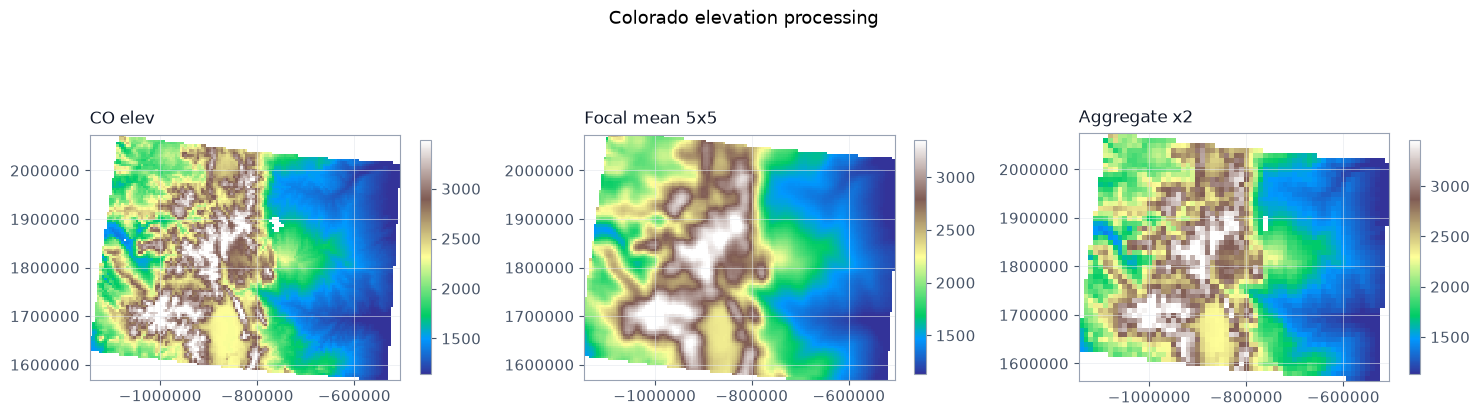

In [20]:
# Output paths for Colorado focal mean and factor-2 aggregate.
co_focal = USA_OUT / "co_elev_focal_mean.tif"  # 5x5 mean of CO elevation
co_agg = USA_OUT / "co_elev_agg_x2.tif"  # coarsened CO elevation
# Smooth with a 5x5 mean window, then coarsen by factor 2.
focal_statistics(co_elev, co_focal, statistic="mean", size=5, overwrite=True)
aggregate(co_elev, co_agg, factor=2, method="average", overwrite=True)

# Stack original and focal-mean into a multi-band GeoTIFF.
stack_path = USA_OUT / "co_elev_stack.tif"  # two-band stack path
stack([co_elev, co_focal], stack_path, overwrite=True)
# Confirm the stack has two bands and report its size.
with open_raster_data(stack_path) as ds:
    print(f"stack bands: {ds.band_count}  size={ds.width}x{ds.height}")

# Three-panel figure: original / focal mean / aggregate.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rasters = [co_elev, co_focal, co_agg]  # paths for the three panels
titles = ["CO elev", "Focal mean 5x5", "Aggregate x2"]  # panel titles

# Plot each Colorado product into its axes.
for ax, raster, title in zip(axes, rasters, titles):
    plot_raster(
        raster,  # raster path
        ax=ax,  # target axes
        title=title,  # panel title
        cmap="terrain",  # elevation colormap
        kind="general",  # single-band continuous display
        robust=True,  # percentile stretch
        show=False,  # defer display
    )
fig.suptitle("Colorado elevation processing", y=1.05)  # shared figure title
fig.tight_layout(rect=[0, 0, 1, 0.95])  # leave room for the suptitle
plt.show()  # render the Colorado processing figure


### Zonal statistics

Mean / min / max elevation by Colorado county (`CO_COUNTY_PROJ.shp`), analogous to
R `raster::extract(..., fun=mean)`. Zones and raster must share a CRS: both use
the Albers-style projected system here. `zone_field="COUNTY_ID"` groups by county id.


counties exist: True


,COUNTY_ID,count,min,max,mean,sum
0,1,119,1395.391357,1703.119995,1551.962710,184683.562500
1,3,75,2292.652100,3390.320068,2369.748151,177731.111328
2,5,76,1486.479980,1847.181763,1661.605721,126282.034790
3,7,141,1967.947388,3566.000000,2513.233076,354365.863770
4,9,263,1082.181763,1567.333374,1311.459547,344913.860962
5,11,158,1147.272705,1428.560059,1261.429516,199305.863525
6,13,77,1512.428589,3532.600098,2285.754330,176003.083374
7,14,5,1575.454590,1683.900024,1621.171484,8105.857422
8,15,105,2244.899902,3731.833252,3020.286368,317130.068604
9,17,184,1191.640015,1573.217407,1330.248976,244765.811646


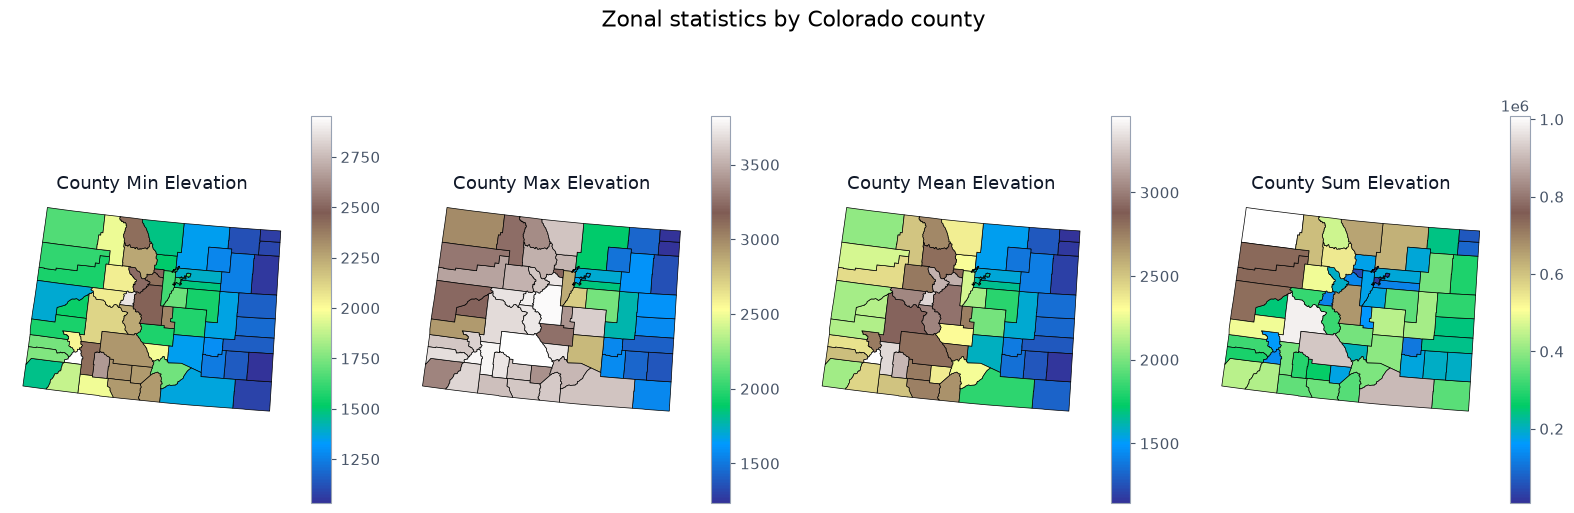

In [21]:
# Path to Colorado counties in the same projected CRS as CO_ELEV.
counties = USA / "CO_COUNTY_PROJ.shp"
print(f"counties exist: {counties.exists()}")  # confirm the shapefile is present

# Summarize elevation inside each county polygon (grouped by COUNTY_ID).
rows = zonal_stats(
    co_elev,  # Colorado elevation raster
    counties,  # county polygon zones
    zone_field="COUNTY_ID",  # group zones by county id
    stats=("count", "min", "max", "mean", "sum"),  # requested summary stats
)
# Convert the list of zone dicts into a DataFrame for display and joining.
zonal_df = pd.DataFrame(rows)
display(zonal_df.head(10))  # preview the first 10 zone rows

# GeoPandas is used to join stats back onto county polygons for choropleth maps.
import geopandas as gpd

# Keep county id, name, and geometry for the join / plot.
gdf = gpd.read_file(counties)[["COUNTY_ID", "COUNTY", "geometry"]]
# Align join key dtypes, then keep a GeoDataFrame so .plot() draws polygons.
zonal_df["COUNTY_ID"] = zonal_df["COUNTY_ID"].astype(gdf["COUNTY_ID"].dtype)
merged = gdf.merge(zonal_df, on="COUNTY_ID", how="left")  # left join keeps all counties

# Four choropleth panels for min / max / mean / sum elevation.
statnames = ["min", "max", "mean", "sum"]  # columns to map
titles = [
    "County Min Elevation",
    "County Max Elevation",
    "County Mean Elevation",
    "County Sum Elevation",
]
fig, axes = plt.subplots(1, len(statnames), figsize=(16, 5))  # one row of panels

# Plot each statistic as a county choropleth.
for ax, stat, title in zip(axes, statnames, titles):
    merged.plot(
        column=stat,  # attribute to color by
        cmap="terrain",  # elevation-friendly colormap
        legend=True,  # show a legend for the color scale
        ax=ax,  # target axes
        edgecolor="black",  # county outlines
        linewidth=0.5,  # thin outlines
        missing_kwds={"color": "lightgrey"},  # counties with no stats
    )
    ax.set_title(title)  # panel title
    ax.set_axis_off()  # hide axes for a clean map

fig.suptitle("Zonal statistics by Colorado county", y=1.02, fontsize=16)  # shared title
fig.tight_layout(rect=[0, 0, 1, 0.95])  # leave room for the suptitle
plt.show()  # render the zonal statistics figure


### Clip Onondaga mosaic

Clip by projected bounds, same pattern as the Bangladesh DEM clip.


full bounds: Bounds(1563322.7032641422, 751976.4158569482, 1624168.0782641422, 818192.4158569482)
clip bounds: (1578534.0470141422, 768530.4158569482, 1608956.7345141422, 801638.4158569482)
path:    onondaga_clip.tif
size:    339 x 267  bands=1
res:     89.7424 x 124.0000
bounds:  Bounds(1578534.0470141422, 768530.4158569482, 1608956.7345141422, 801638.4158569482)
crs:     PROJCS["unnamed",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",37.5],PARAMETER["longitude_of_center",-96],PARAMETER["standard_parallel_1",29.5],PARAMETER["standard_parallel_2",45.5],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
nodata:  -3.399999952

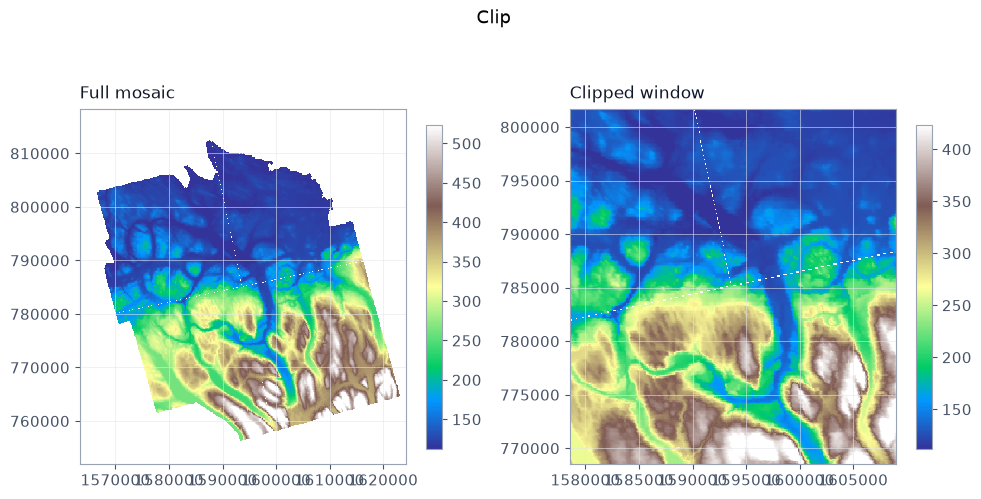

In [22]:
# Open the Onondaga mosaic and build a central window from its projected bounds.
with open_raster_data(usa_mosaic) as ds:
    # Unpack full extent as (minx, miny, maxx, maxy) in the raster CRS.
    minx, miny, maxx, maxy = ds.bounds.to_tuple()
    # Central window ~ middle 50% of the mosaic.
    mid_bounds = (
        minx + 0.25 * (maxx - minx),  # inset 25% from the west
        miny + 0.25 * (maxy - miny),  # inset 25% from the south
        maxx - 0.25 * (maxx - minx),  # inset 25% from the east
        maxy - 0.25 * (maxy - miny),  # inset 25% from the north
    )
    print("full bounds:", ds.bounds)  # print the full mosaic extent
    print("clip bounds:", mid_bounds)  # print the crop window

# Destination path for the clipped Onondaga window.
usa_clip = USA_OUT / "onondaga_clip.tif"
# Crop the mosaic to the central projected bounds.
clip(usa_mosaic, usa_clip, bounds=mid_bounds, overwrite=True)
# Print metadata for the clipped result.
show_raster(usa_clip)

# Side-by-side map: full mosaic vs clipped window.
fig, axes = plot_rasters(
    [usa_mosaic, usa_clip],
    titles=["Full mosaic", "Clipped window"],
    figsize=(10, 5),
    cmap="terrain",
    kind="general",
    robust=True,
    show=False,
)
fig.suptitle("Clip", y=1.02)  # shared figure title
fig.tight_layout()  # tighten spacing
plt.show()  # render the comparison figure


## Summary

| Operation | Function | Bangladesh / USA demo |
|---|---|---|
| Create empty raster | `create` | template beside BTM DEM |
| Metadata edit | `edit` | scale / offset / description |
| Format / dtype | `convert` | GeoTIFF copy |
| Pixel resize | `resize` | 50% width/height |
| Unscale | `unscale` | reverse demo scale/offset |
| Fill holes | `fill_nodata` | synthetic hole in clip |
| Focal / neighbors | `focal_statistics`, `neighbors` | 9x9 mean / sum |
| Algebra | `calc`, `raster_algebra` | m -> ft |
| Blend / compare | `blend`, `compare` | focal blend; self-compare |
| Clip | `clip` | southern hills; Onondaga center |
| Reclassify | `reclassify` | elevation classes |
| Resample family | `resample`, `aggregate`, `disaggregate` | 250<->500<->50 m |
| Mosaic / stack | `mosaic`, `stack` | `HILLY_DEM`; Onondaga tiles; CO stack |
| Summarize / zones | `summarize_raster`, `zonal_stats` | DEM stats; CO counties |
| Vector -> raster | `rasterize` | district Boro production (250 m) |
| Vectorize / distance | `polygonize`, `proximity`, `contour` | reclass polygons; high-elev distance |
| Color relief | `color_map` | GDAL color text -> RGB |

Outputs:

* `Data/00_shared/raster_data/output_folder/bangladesh/ops/`
* `Data/00_shared/raster_data/output_folder/usa/ops/`


### Further reading

1. [GDAL raster programs](https://gdal.org/en/stable/programs/gdal_raster.html)
2. [Raster data manipulation (terra / R)](https://rspatial.org/spatial/8-rastermanip.html)
3. `geolattice.raster.basic_raster_operation`: source for every helper used here
4. Previous notebooks: `02_01_read_write_raster_data.ipynb`, `02_02_map_projection_raster.ipynb`
5. R companions: `R_Code/working-with-raster-data-r.qmd`, `R_Code/working-with-raster-data.Rmd`
